# Commodity tercile strategies vs buy and hold

Aryan Meena, with Prof. Eugene Pinsky (Boston University).

Data is my Bloomberg pull of the Bloomberg Commodity Index total-return sub-indices (`data/Commodities_TR_Futures.xlsx`, not included in the repo because of the licence). Sample runs from 2001-01-05 to 2026-09-17.

**The rule.** At each rebalance close I rank the commodities by their total return over the lookback, cut the ranking into Best / Middle / Worst groups and hold each group equal weight until the next rebalance. The ranking only uses prices up to that close, and the first return a portfolio earns is close to next close. Costs are charged per unit of one-way turnover on the first day of each holding period.

**Benchmark.** Buy and hold is the Bloomberg Commodity Index total return (BCOMTR). The dotted line in the charts is 1/N equal weight of the same commodities.

The first run reads the Bloomberg workbook (10 to 30 seconds) and caches it in `cache/`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))      # run the notebook from the repo root
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from commodity_research.loader import Data
from commodity_research import grid as G, compare as C
from commodity_research.config import OUT
OUT.mkdir(exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
data = Data()
print('Sessions:', len(data.dates), '| first evaluated day:', data.dates[G.START_POS + 1].date(), '| last:', data.dates[-1].date())

Sessions: 6722 | first evaluated day: 2001-01-05 | last: 2026-09-17


## 1. Run all 1,568 configurations

In [2]:
# one gross run per configuration, net results at any cost come from the turnover series
grid, bh_final = G.run_grid(data)
bh = G.buy_and_hold(data).values
bh_dd = G.max_drawdown(bh, np.zeros_like(bh), 0); bh_sh = G.sharpe(bh, np.zeros_like(bh), 0)
print(f'BCOMTR buy & hold: $100 -> ${bh_final:,.0f} | max drawdown {bh_dd:.1%} | Sharpe {bh_sh:.2f}')
grid.to_csv(OUT / 'all_configurations_summary.csv', index=False)

Top6 2-2-2 done


Top7 3-2-2 done


Top7 2-3-2 done


Top7 2-2-3 done


Top8 3-3-2 done


Top8 3-2-3 done


Top8 2-3-3 done


Top9 3-3-3 done


BCOMTR buy & hold: $100 -> $206 | max drawdown -73.2% | Sharpe 0.26


## 2. Top 5 strategies at each rebalance frequency
Ranked by gross final value. Some splits give the exact same portfolio (for example Worst 2 of 7 under 3-2-2 and 2-3-2), and those are listed once.

In [3]:
top = C.top_per_frequency(grid, n=5)
# 1/N of all nine at each frequency, the dotted reference line
ew = {f: 100 * np.prod(1 + G.equal_weight(data, 'Top9', f)[0].values) for f in G.FREQS}
top[['Frequency', 'Rank', 'Strategy', 'Universe', 'Split', 'Final $0bp', 'Final $1bp', 'Final $2bp', 'Final $5bp', 'Breakeven bp vs B&H']].round(1)

,Frequency,Rank,Strategy,Universe,Split,Final $0bp,Final $1bp,Final $2bp,Final $5bp,Breakeven bp vs B&H
0,Daily,1,"Worst 2 of top 7 (3-2-2), 1d lookback",Top7,3-2-2,5117.2,2031.1,806.0,50.3,3.5
1,Daily,2,"Worst 3 of top 7 (2-2-3), 1d lookback",Top7,2-2-3,4032.9,1872.9,869.7,87.0,3.9
2,Daily,3,"Worst 2 of top 6 (2-2-2), 1d lookback",Top6,2-2-2,3645.4,1525.2,638.0,46.7,3.3
3,Daily,4,"Worst 3 of top 9 (3-3-3), 1d lookback",Top9,3-3-3,3364.8,1401.3,583.5,42.1,3.2
4,Daily,5,"Worst 3 of top 8 (3-2-3), 1d lookback",Top8,3-2-3,1991.7,871.3,381.1,31.9,2.7
5,Weekly,1,"Middle 3 of top 9 (3-3-3), 10d lookback",Top9,3-3-3,1379.1,1177.2,1004.9,625.0,12.0
6,Weekly,2,"Middle 2 of top 7 (2-2-3), 10d lookback",Top7,2-2-3,1189.7,1003.9,847.1,508.8,10.3
7,Weekly,3,"Middle 2 of top 6 (2-2-2), 10d lookback",Top6,2-2-2,1188.9,1017.2,870.3,544.9,11.2
8,Weekly,4,"Middle 3 of top 7 (2-3-2), 10d lookback",Top7,2-3-2,1171.6,1027.6,901.2,608.0,13.2
9,Weekly,5,"Middle 2 of top 7 (3-2-2), 10d lookback",Top7,3-2-2,1014.2,856.6,723.5,435.8,9.4


## 3. Final value of $100 vs buy and hold

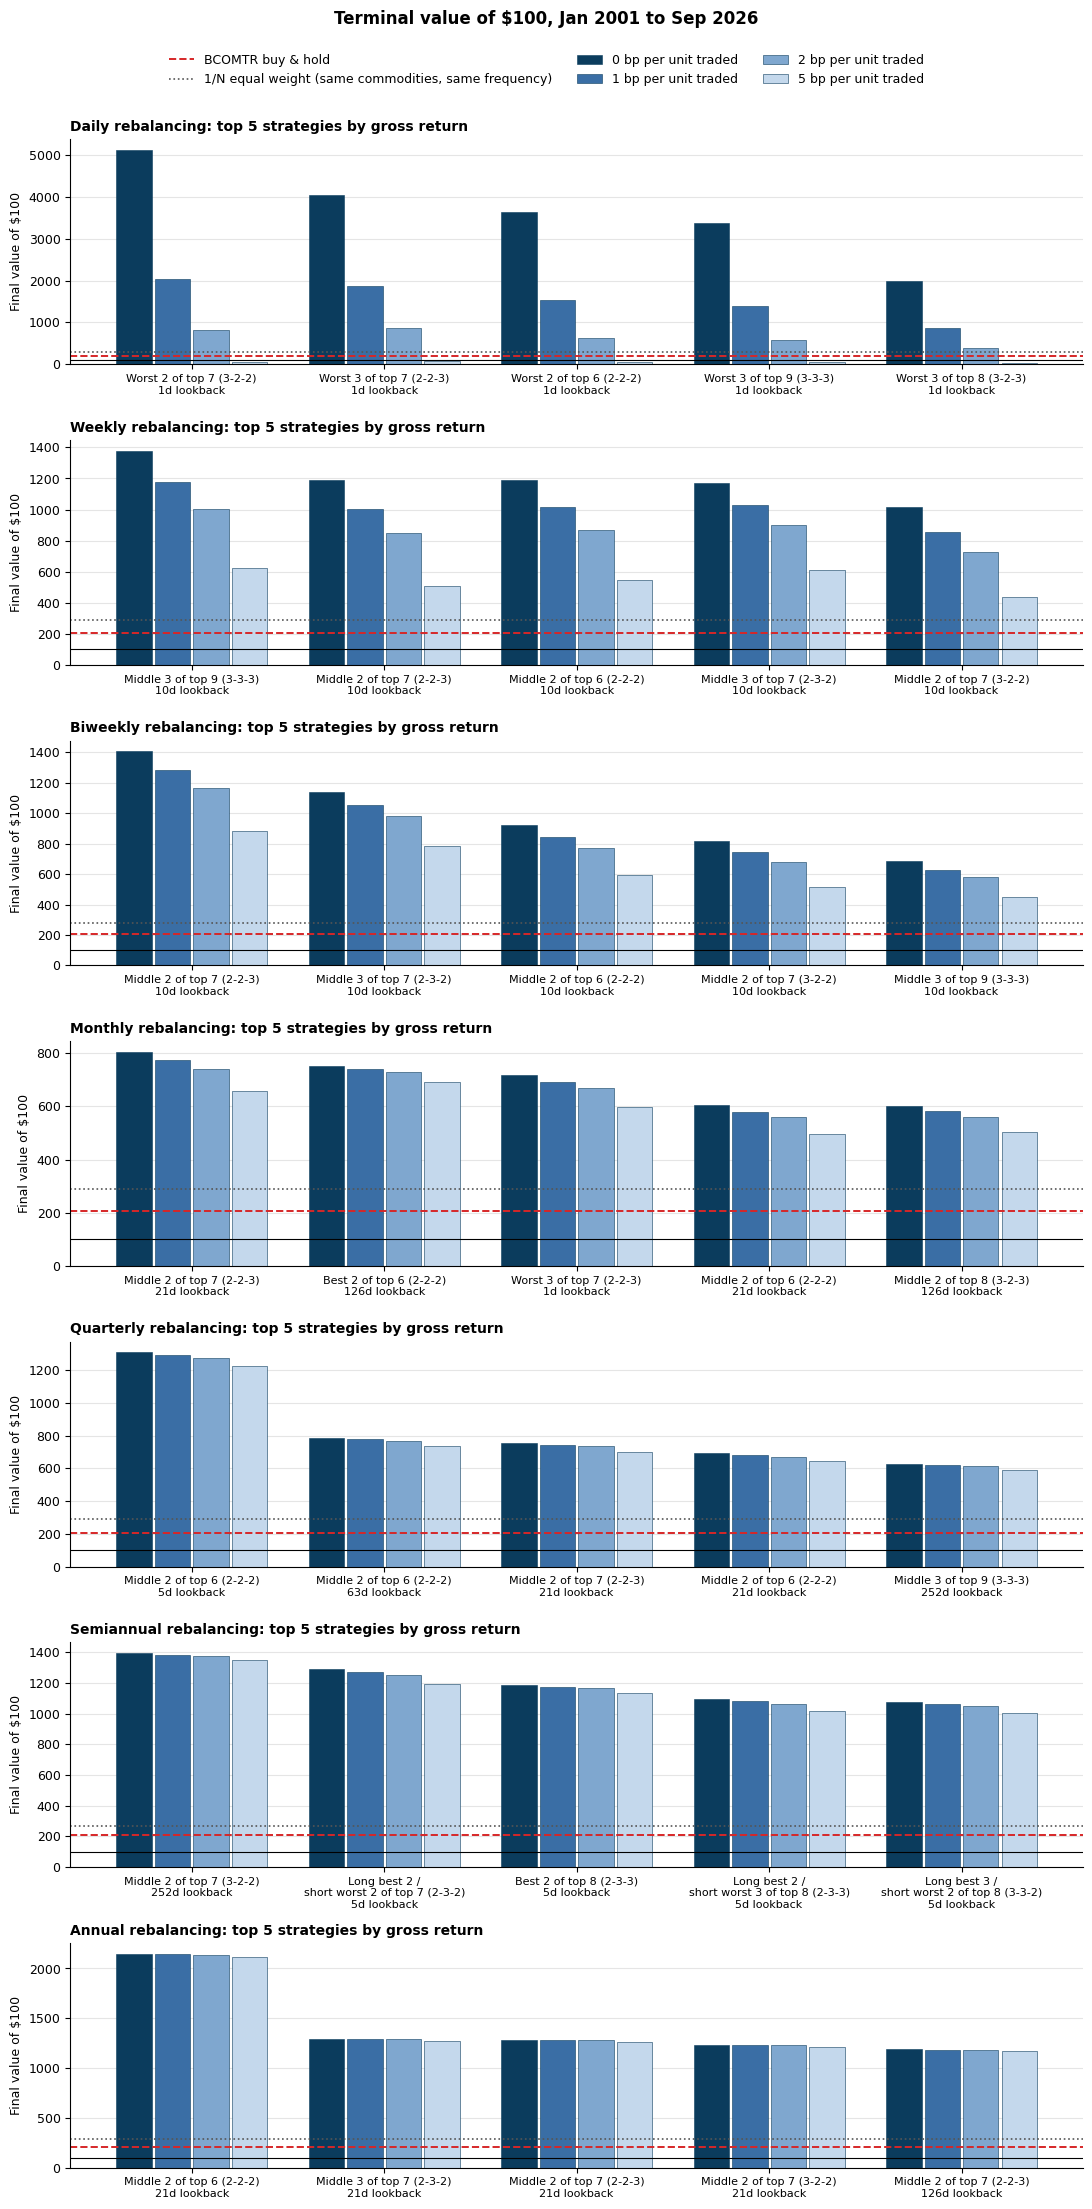

In [4]:
fig = C.bar_chart(top, bh_final, 'Final', path=OUT / 'fig_final_value_vs_buy_hold.png', ew=ew)
plt.show()

## 4. Maximum drawdown vs buy and hold

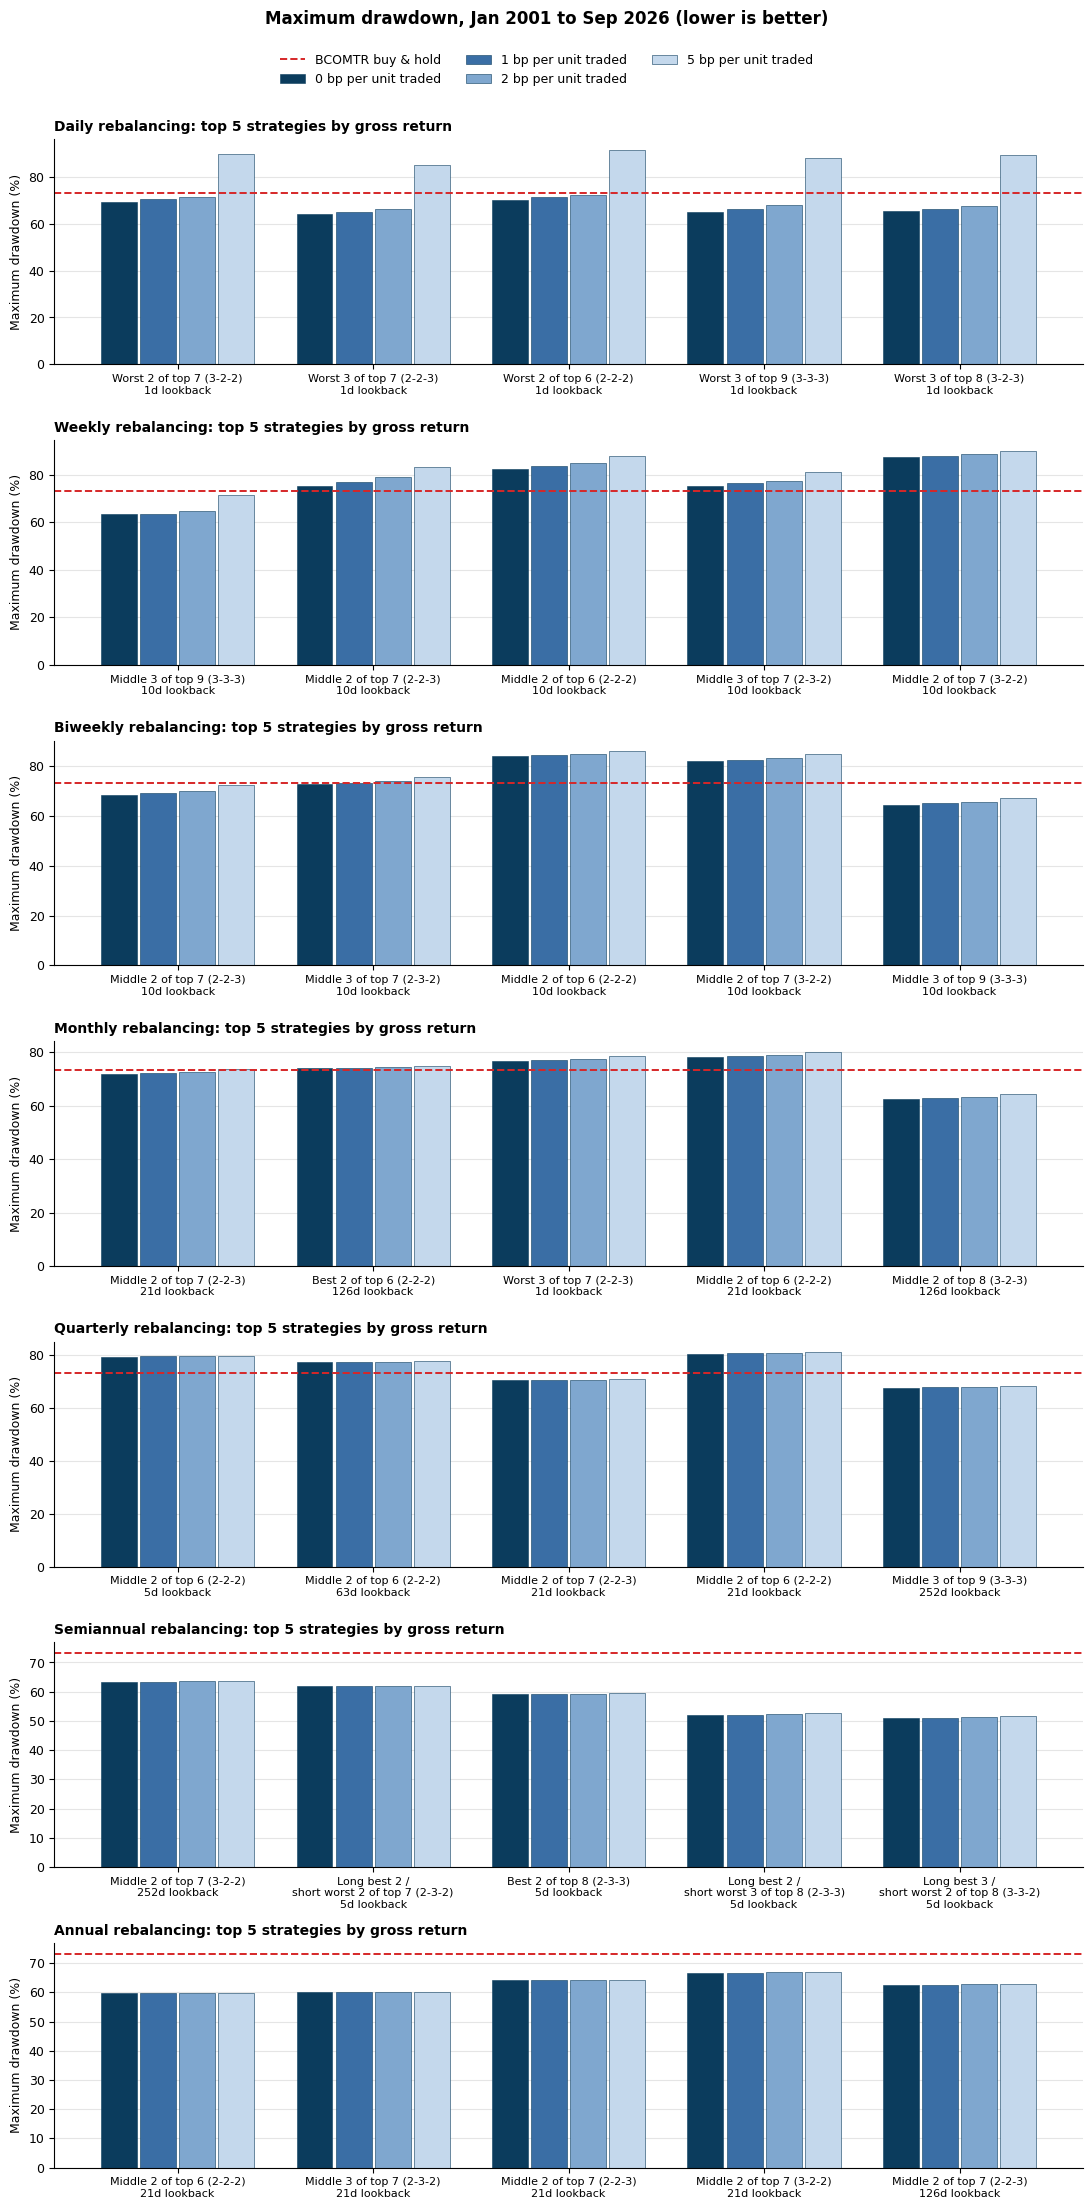

In [5]:
fig = C.bar_chart(top, bh_dd, 'MaxDD', path=OUT / 'fig_max_drawdown_vs_buy_hold.png')
plt.show()

## 5. Cost ladder: how many basis points until each strategy only matches buy and hold?
Blue is buy and hold, green beats it, light red trails it. The same table is saved to `outputs/Top5_vs_BuyHold_cost_ladder.xlsx`.

In [6]:
tab, cost_cols, series = C.cost_ladder(data, top, bh_final)
ew_tab = pd.DataFrame({'Frequency': G.FREQS, **{u: [100 * np.prod(1 + G.equal_weight(data, u, f)[0].values) for f in G.FREQS] for u in ['Top6', 'Top7', 'Top8', 'Top9']}})
C.write_excel(tab, cost_cols, bh_final, bh_dd, bh_sh, OUT / 'Top5_vs_BuyHold_cost_ladder.xlsx', ew_table=ew_tab)
# same colours as the Excel file, green above buy and hold, red below
vc = [f'{b:g} bp' for b in cost_cols]
def colour(v):
    return 'background-color: #C6EFCE' if v > bh_final else 'background-color: #FFC7CE'
show = tab[['Frequency', 'Rank', 'Strategy'] + vc + ['Break-even cost vs buy & hold (bp)']]
show.style.format({c: '${:,.0f}' for c in vc} | {'Break-even cost vs buy & hold (bp)': '{:,.1f}'}).map(colour, subset=vc)

,Frequency,Rank,Strategy,0 bp,1 bp,2 bp,3 bp,4 bp,5 bp,7.5 bp,10 bp,15 bp,20 bp,25 bp,30 bp,40 bp,50 bp,75 bp,100 bp,150 bp,200 bp,300 bp,400 bp,500 bp,750 bp,Break-even cost vs buy & hold (bp)
0,Daily,1,"Worst 2 of top 7 (3-2-2), 1d lookback","$5,117","$2,031",$806,$320,$127,$50,$5,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,3.5
1,Daily,2,"Worst 3 of top 7 (2-2-3), 1d lookback","$4,033","$1,873",$870,$404,$187,$87,$13,$2,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,3.9
2,Daily,3,"Worst 2 of top 6 (2-2-2), 1d lookback","$3,645","$1,525",$638,$267,$112,$47,$5,$1,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,3.3
3,Daily,4,"Worst 3 of top 9 (3-3-3), 1d lookback","$3,365","$1,401",$584,$243,$101,$42,$5,$1,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,3.2
4,Daily,5,"Worst 3 of top 8 (3-2-3), 1d lookback","$1,992",$871,$381,$167,$73,$32,$4,$1,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,$0,2.7
5,Weekly,1,"Middle 3 of top 9 (3-3-3), 10d lookback","$1,379","$1,177","$1,005",$858,$732,$625,$421,$283,$128,$58,$26,$12,$2,$0,$0,$0,$0,$0,$0,$0,$0,$0,12.0
6,Weekly,2,"Middle 2 of top 7 (2-2-3), 10d lookback","$1,190","$1,004",$847,$715,$603,$509,$333,$217,$93,$40,$17,$7,$1,$0,$0,$0,$0,$0,$0,$0,$0,$0,10.3
7,Weekly,3,"Middle 2 of top 6 (2-2-2), 10d lookback","$1,189","$1,017",$870,$745,$637,$545,$369,$250,$114,$52,$24,$11,$2,$0,$0,$0,$0,$0,$0,$0,$0,$0,11.2
8,Weekly,4,"Middle 3 of top 7 (2-3-2), 10d lookback","$1,172","$1,028",$901,$790,$693,$608,$438,$315,$164,$85,$44,$23,$6,$2,$0,$0,$0,$0,$0,$0,$0,$0,13.2
9,Weekly,5,"Middle 2 of top 7 (3-2-2), 10d lookback","$1,014",$857,$723,$611,$516,$436,$286,$187,$80,$34,$15,$6,$1,$0,$0,$0,$0,$0,$0,$0,$0,$0,9.4


## 6. Three checks before I believe any of it
**(a) One-day delay.** Trade the day after the signal instead of at the same close.

**(b) Rebalance month.** Run the best annual rule with each of the 12 month-ends as its rebalance date.

**(c) Walk-forward.** Pick the 5 best configurations on 2001 to 2013 only, then run them blind on 2014 to 2026.

In [7]:
from commodity_research.universe import TR, UNIVERSES
from commodity_research import engine as E
s0 = G.START_POS
# buy the k worst performers of the previous day, lag = extra days of delay before trading
def daily_reversal(keys, k, lag):
    P = data.PX[[TR[x] for x in keys]].values; R = P[1:] / P[:-1] - 1; out = []
    for s in range(s0, len(P) - 1):
        w = np.zeros(len(keys)); w[np.argsort(-R[s - 1 - lag], kind='stable')[-k:]] = 1 / k; out.append(R[s] @ w)
    x = np.array(out); return x.mean() / x.std(ddof=1) * np.sqrt(252), 100 * np.prod(1 + x)
rows = []
for u, k in [('Top6', 2), ('Top7', 2), ('Top9', 3)]:
    for lag in [0, 1]:
        sr, fv = daily_reversal(UNIVERSES[u][0], k, lag)
        rows.append({'Universe': u, 'Buy worst': k, 'Execution': 'same close' if lag == 0 else 'next day', 'Sharpe': round(sr, 2), '$100 ->': round(fv)})
print('(a) Daily reversal, gross'); display(pd.DataFrame(rows))

# the best annual rule, restarted from each month-end in turn
P, _, _ = data.prices(UNIVERSES['Top6'][0]); dates = data.dates; n = len(dates)
key = pd.Series(np.asarray(dates.to_period('M')), index=np.arange(n)); me = key.groupby(key).tail(1).index.values
rows = []
for m in range(1, 13):
    pos = me[(dates[me].month == m) & (me > s0) & (me < n - 1)]; reb = np.unique(np.concatenate([[s0], pos]))
    Ws, _ = E.group_weights(P[reb] / P[reb - 21] - 1, (2, 2, 2)); r, _ = E.hold_returns(P, reb, Ws[1]); x = r[s0 + 1:]
    rows.append({'Rebalance month': pd.Timestamp(2000, m, 1).strftime('%B'), 'Sharpe': round(x.mean() / x.std() * np.sqrt(252), 2), '$100 ->': round(100 * np.prod(1 + x))})
print('(b) Middle 2 of top 6, 21d lookback, annual rebalance: result depends on the month'); display(pd.DataFrame(rows))

(a) Daily reversal, gross


,Universe,Buy worst,Execution,Sharpe,$100 ->
0,Top6,2,same close,0.61,3645
1,Top6,2,next day,0.16,111
2,Top7,2,same close,0.67,5117
3,Top7,2,next day,0.16,111
4,Top9,3,same close,0.67,3365
5,Top9,3,next day,0.34,389


(b) Middle 2 of top 6, 21d lookback, annual rebalance: result depends on the month


,Rebalance month,Sharpe,$100 ->
0,January,0.52,1302
1,February,0.38,545
2,March,0.25,228
3,April,0.52,1164
4,May,0.31,327
5,June,0.16,115
6,July,0.37,504
7,August,0.42,700
8,September,0.28,262
9,October,0.27,248


In [8]:
# choose on 2001-2013 by Sharpe, then look at 2014-2026 only once
cut = pd.Timestamp('2013-12-31'); rows = []
ins = {}
for i, r in grid.iterrows():
    g, c = G.config_series(data, r.Universe, r.Split, r.Lookback, r.Frequency, r.Group)
    a = g[g.index <= cut]; ins[i] = (a.mean() / a.std() * np.sqrt(252), g[g.index > cut])
best = sorted(ins, key=lambda i: ins[i][0], reverse=True)[:5]
for i in best:
    b = ins[i][1]; r = grid.loc[i]
    rows.append({'Strategy': G.label(r) + f' | {r.Frequency}', 'Sharpe 2001-13 (chosen on this)': round(ins[i][0], 2),
                 'Sharpe 2014-26 (blind)': round(b.mean() / b.std() * np.sqrt(252), 2), '$100 in 2014 -> 2026': round(100 * np.prod(1 + b))})
bh2 = G.buy_and_hold(data); bh2 = bh2[bh2.index > cut]
print(f'(c) Walk-forward. Buy & hold over 2014-26 turned $100 into ${100 * np.prod(1 + bh2):,.0f}')
pd.DataFrame(rows)

(c) Walk-forward. Buy & hold over 2014-26 turned $100 into $149


,Strategy,Sharpe 2001-13 (chosen on this),Sharpe 2014-26 (blind),$100 in 2014 -> 2026
0,"Long best 2 / short worst 3 of top 8 (2-3-3), ...",0.92,0.08,71
1,"Long best 3 / short worst 3 of top 9 (3-3-3), ...",0.90,-0.00,60
2,"Best 3 of top 9 (3-3-3), 5d lookback | Semiannual",0.88,0.11,97
3,"Long best 2 / short worst 3 of top 7 (2-2-3), ...",0.86,0.06,65
4,"Best 2 of top 7 (2-3-2), 5d lookback | Semiannual",0.86,0.12,93


## What I take from this
* Before costs the best strategies beat buy and hold by a wide margin, but the daily "buy yesterday's losers" rules stop beating it at only 3 to 4 bp.
* The slow rules (quarterly to annual) survive large costs, but the best of them depends on the rebalance month and mostly on not holding natural gas.
* Chosen on the first half and run blind on the second, the top strategies fall below buy and hold. The grid finds what worked in the past, not what works next.